In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Konfigurasi global font publikasi (Times New Roman + STIX Math)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

# Definisi direktori file
build_dir = r"E:\Tugas Akhir\New Firmware\build"
data_dir  = r"E:\Tugas Akhir\New Firmware\Sim\data"

def resolve_file(directory, exact_candidates, wildcard_pattern=None):
    for name in exact_candidates:
        full_path = os.path.join(directory, name)
        if os.path.isfile(full_path):
            return full_path
    if wildcard_pattern:
        matches = sorted(glob.glob(os.path.join(directory, wildcard_pattern)))
        if matches:
            return matches[0]
    return None

# 1. Muat output C++ terbaru (Trajektori 25 kolom & Diagnostik EKF 16 kolom)
path_ekf  = os.path.join(build_dir, 'ins_ekf_fused_trajectory.csv')
path_diag = os.path.join(build_dir, 'ekf_gnss_diagnostics.csv')

df_ekf  = pd.read_csv(path_ekf)
df_diag = pd.read_csv(path_diag)

# 2. Muat dataset referensi GNSS, Pure INS, dan Attitude PX4 secara otomatis
path_gps = resolve_file(
    data_dir,
    ['vehicle_gps_position.csv', 'vehicle_gps_position_0.csv', 'Dataset_vehicle_gps_position_0.csv'],
    '*vehicle_gps_position*.csv'
)
path_att = resolve_file(
    data_dir,
    ['vehicle_attitude.csv', 'vehicle_attitude_0.csv', 'Dataset_vehicle_attitude_0.csv'],
    '*vehicle_attitude*.csv'
)
path_ins_xlsx = resolve_file(
    data_dir,
    ['INS_GNSS_Analysis.xlsx', 'Dataset_INS_GNSS_Analysis.xlsx'],
    '*INS_GNSS_Analysis*.xlsx'
)

if path_gps is None:
    raise FileNotFoundError(f"File GPS tidak ditemukan di {data_dir}")

df_gps = pd.read_csv(path_gps)
df_ins = pd.read_excel(path_ins_xlsx, sheet_name='INS_Estimated_Trajectory') if path_ins_xlsx else None
df_att = pd.read_csv(path_att) if path_att else None

# Pastikan skala koordinat GPS dalam derajat & meter (mendukung format PX4 lama maupun baru)
if 'latitude_deg' not in df_gps.columns and 'lat' in df_gps.columns:
    df_gps['latitude_deg'] = df_gps['lat'] * 1e-7
if 'longitude_deg' not in df_gps.columns and 'lon' in df_gps.columns:
    df_gps['longitude_deg'] = df_gps['lon'] * 1e-7
if 'altitude_ellipsoid_m' not in df_gps.columns:
    if 'alt_ellipsoid' in df_gps.columns:
        df_gps['altitude_ellipsoid_m'] = df_gps['alt_ellipsoid'] * 1e-3
    elif 'altitude_msl_m' in df_gps.columns:
        df_gps['altitude_ellipsoid_m'] = df_gps['altitude_msl_m']

# Seragamkan sumbu waktu ke detik relatif mulai dari awal simulasi (t0)
t0 = df_ekf['timestamp'].iloc[0]
df_ekf['t_sec']  = df_ekf['timestamp'] - t0
df_diag['t_sec'] = df_diag['timestamp'] - t0
df_gps['t_sec']  = (df_gps['timestamp'] * 1e-6) - t0

if df_ins is not None:
    df_ins['t_sec'] = df_ins['timestamp'] - t0
if df_att is not None:
    df_att['t_sec'] = (df_att['timestamp'] * 1e-6) - t0

print(f"File GPS ditemukan     : {os.path.basename(path_gps)}")
print(f"File Attitude          : {os.path.basename(path_att) if path_att else 'Tidak ditemukan'}")
print(f"File Pure INS (Excel)  : {os.path.basename(path_ins_xlsx) if path_ins_xlsx else 'Tidak ditemukan'}")
print("-" * 52)
print(f"Durasi penerbangan     : {df_ekf['t_sec'].max():.2f} detik")
print(f"Jumlah data EKF        : {len(df_ekf)} baris ({len(df_ekf.columns)} kolom)")
print(f"Jumlah update GNSS EKF : {len(df_diag)} baris ({len(df_diag.columns)} kolom)")
print(f"Jumlah data GNSS raw   : {len(df_gps)} baris")

File GPS ditemukan     : Dataset_vehicle_gps_position_0.csv
File Attitude          : Tidak ditemukan
File Pure INS (Excel)  : Dataset_INS_GNSS_Analysis.xlsx
----------------------------------------------------
Durasi penerbangan     : 128.77 detik
Jumlah data EKF        : 21233 baris (26 kolom)
Jumlah update GNSS EKF : 1030 baris (17 kolom)
Jumlah data GNSS raw   : 1031 baris


In [2]:
# Titik referensi awal penerbangan (Datum Home dari sampel GNSS valid pertama)
lat0 = np.radians(df_gps['latitude_deg'].iloc[0])
lon0 = np.radians(df_gps['longitude_deg'].iloc[0])
h0   = df_gps['altitude_ellipsoid_m'].iloc[0]

# Konstanta Elipsoid WGS-84 (Groves Eq. 2.105 & 2.106)
R0     = 6378137.0
E_SQR  = 0.00669437999014
sin_L0 = np.sin(lat0)
RN = R0 * (1.0 - E_SQR) / ((1.0 - E_SQR * sin_L0**2)**1.5)
RE = R0 / np.sqrt(1.0 - E_SQR * sin_L0**2)

def geodetic_to_ned(lat_deg, lon_deg):
    north_m = (np.radians(lat_deg) - lat0) * (RN + h0)
    east_m  = (np.radians(lon_deg) - lon0) * (RE + h0) * np.cos(lat0)
    return north_m, east_m

df_gps['North_m'], df_gps['East_m'] = geodetic_to_ned(df_gps['latitude_deg'], df_gps['longitude_deg'])
df_ekf['North_m'], df_ekf['East_m'] = geodetic_to_ned(df_ekf['latitude_deg'], df_ekf['longitude_deg'])

if df_ins is not None:
    df_ins['North_m'], df_ins['East_m'] = geodetic_to_ned(df_ins['latitude_deg'], df_ins['longitude_deg'])

# Konversi kuaternion PX4 (FRD-to-NED) ke sudut Euler Z-Y-X dalam derajat
if df_att is not None:
    q0 = df_att['q[0]'].values
    q1 = df_att['q[1]'].values
    q2 = df_att['q[2]'].values
    q3 = df_att['q[3]'].values

    df_att['roll_deg']  = np.degrees(np.arctan2(2.0 * (q0 * q1 + q2 * q3), 1.0 - 2.0 * (q1**2 + q2**2)))
    df_att['pitch_deg'] = np.degrees(np.arcsin(np.clip(2.0 * (q0 * q2 - q3 * q1), -1.0, 1.0)))
    df_att['yaw_deg']   = np.degrees(np.arctan2(2.0 * (q0 * q3 + q1 * q2), 1.0 - 2.0 * (q2**2 + q3**2)))

In [3]:
# Ambil sampel GNSS dalam rentang waktu simulasi
mask_valid = (df_gps['t_sec'] >= df_ekf['t_sec'].min()) & (df_gps['t_sec'] <= df_ekf['t_sec'].max())
gps_ref = df_gps[mask_valid].reset_index(drop=True)

def evaluasi_error(df_est, ref):
    t_ref = ref['t_sec'].values
    t_est = df_est['t_sec'].values

    err_n  = np.interp(t_ref, t_est, df_est['North_m'].values) - ref['North_m'].values
    err_e  = np.interp(t_ref, t_est, df_est['East_m'].values) - ref['East_m'].values
    err_2d = np.sqrt(err_n**2 + err_e**2)
    err_h  = np.interp(t_ref, t_est, df_est['height_m'].values) - ref['altitude_ellipsoid_m'].values
    err_vn = np.interp(t_ref, t_est, df_est['v_N'].values) - ref['vel_n_m_s'].values
    err_ve = np.interp(t_ref, t_est, df_est['v_E'].values) - ref['vel_e_m_s'].values
    err_vd = np.interp(t_ref, t_est, df_est['v_D'].values) - ref['vel_d_m_s'].values

    hasil = []
    daftar_variabel = [
        ('Posisi Horizontal 2D (m)', err_2d),
        ('Posisi North (m)', err_n),
        ('Posisi East (m)', err_e),
        ('Ketinggian / Altitude (m)', err_h),
        ('Kecepatan North v_N (m/s)', err_vn),
        ('Kecepatan East v_E (m/s)', err_ve),
        ('Kecepatan Down v_D (m/s)', err_vd),
    ]
    for nama, e in daftar_variabel:
        mae  = np.mean(np.abs(e))
        mse  = np.mean(e**2)
        rmse = np.sqrt(mse)
        maks = np.max(np.abs(e))
        hasil.append({'Parameter': nama, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'Max Error': maks})

    seri_error = {
        't': t_ref, 'err_2d': err_2d, 'err_n': err_n, 'err_e': err_e,
        'err_h': err_h, 'err_vn': err_vn, 'err_ve': err_ve, 'err_vd': err_vd
    }
    return pd.DataFrame(hasil), seri_error

df_err_ekf, seri_ekf = evaluasi_error(df_ekf, gps_ref)

if df_ins is not None:
    df_err_ins, seri_ins = evaluasi_error(df_ins, gps_ref)
    tabel_perbandingan = pd.DataFrame({
        'Parameter': df_err_ekf['Parameter'],
        'Pure INS RMSE': df_err_ins['RMSE'],
        'INS+EKF MAE': df_err_ekf['MAE'],
        'INS+EKF MSE': df_err_ekf['MSE'],
        'INS+EKF RMSE': df_err_ekf['RMSE'],
        'INS+EKF Max Error': df_err_ekf['Max Error'],
        'Reduksi Error (%)': (1.0 - df_err_ekf['RMSE'] / df_err_ins['RMSE']) * 100.0
    })
else:
    tabel_perbandingan = df_err_ekf.rename(columns={
        'MAE': 'INS+EKF MAE', 'MSE': 'INS+EKF MSE',
        'RMSE': 'INS+EKF RMSE', 'Max Error': 'INS+EKF Max Error'
    })

print("=== Evaluasi Error Posisi dan Kecepatan (INS+EKF vs. Raw GPS) ===")
display(tabel_perbandingan.round(4))

# Evaluasi Sikap (Roll, Pitch, Yaw) terhadap Referensi PX4 vehicle_attitude
if df_att is not None:
    mask_att = (df_att['t_sec'] >= df_ekf['t_sec'].min()) & (df_att['t_sec'] <= df_ekf['t_sec'].max())
    att_ref = df_att[mask_att].reset_index(drop=True)
    t_att = att_ref['t_sec'].values

    def wrap_angle_deg(diff_deg):
        return (diff_deg + 180.0) % 360.0 - 180.0

    err_roll  = wrap_angle_deg(np.interp(t_att, df_ekf['t_sec'].values, df_ekf['roll_deg'].values)  - att_ref['roll_deg'].values)
    err_pitch = wrap_angle_deg(np.interp(t_att, df_ekf['t_sec'].values, df_ekf['pitch_deg'].values) - att_ref['pitch_deg'].values)
    err_yaw   = wrap_angle_deg(np.interp(t_att, df_ekf['t_sec'].values, df_ekf['yaw_deg'].values)   - att_ref['yaw_deg'].values)

    att_rows = []
    for nama, e in [('Roll [deg]', err_roll), ('Pitch [deg]', err_pitch), ('Yaw [deg]', err_yaw)]:
        att_rows.append({
            'Parameter Sikap': nama,
            'MAE': np.mean(np.abs(e)),
            'RMSE': np.sqrt(np.mean(e**2)),
            'Max Error': np.max(np.abs(e))
        })
    print("\n=== Evaluasi Error Sikap (INS+EKF vs. PX4 vehicle_attitude) ===")
    display(pd.DataFrame(att_rows).round(4))

=== Evaluasi Error Posisi dan Kecepatan (INS+EKF vs. Raw GPS) ===


,Parameter,Pure INS RMSE,INS+EKF MAE,INS+EKF MSE,INS+EKF RMSE,INS+EKF Max Error,Reduksi Error (%)
0,Posisi Horizontal 2D (m),2324.5072,0.0618,0.0051,0.0717,0.1480,99.9969
1,Posisi North (m),1630.9753,0.0290,0.0014,0.0371,0.1155,99.9977
2,Posisi East (m),1656.2769,0.0478,0.0038,0.0614,0.1422,99.9963
3,Ketinggian / Altitude (m),14.2745,0.2160,0.0655,0.2559,0.6232,98.2076
4,Kecepatan North v_N (m/s),39.6192,0.0548,0.0052,0.0718,0.2816,99.8188
5,Kecepatan East v_E (m/s),34.3184,0.0736,0.0095,0.0973,0.3721,99.7165
6,Kecepatan Down v_D (m/s),0.9119,0.0698,0.0078,0.0886,0.4249,90.2842


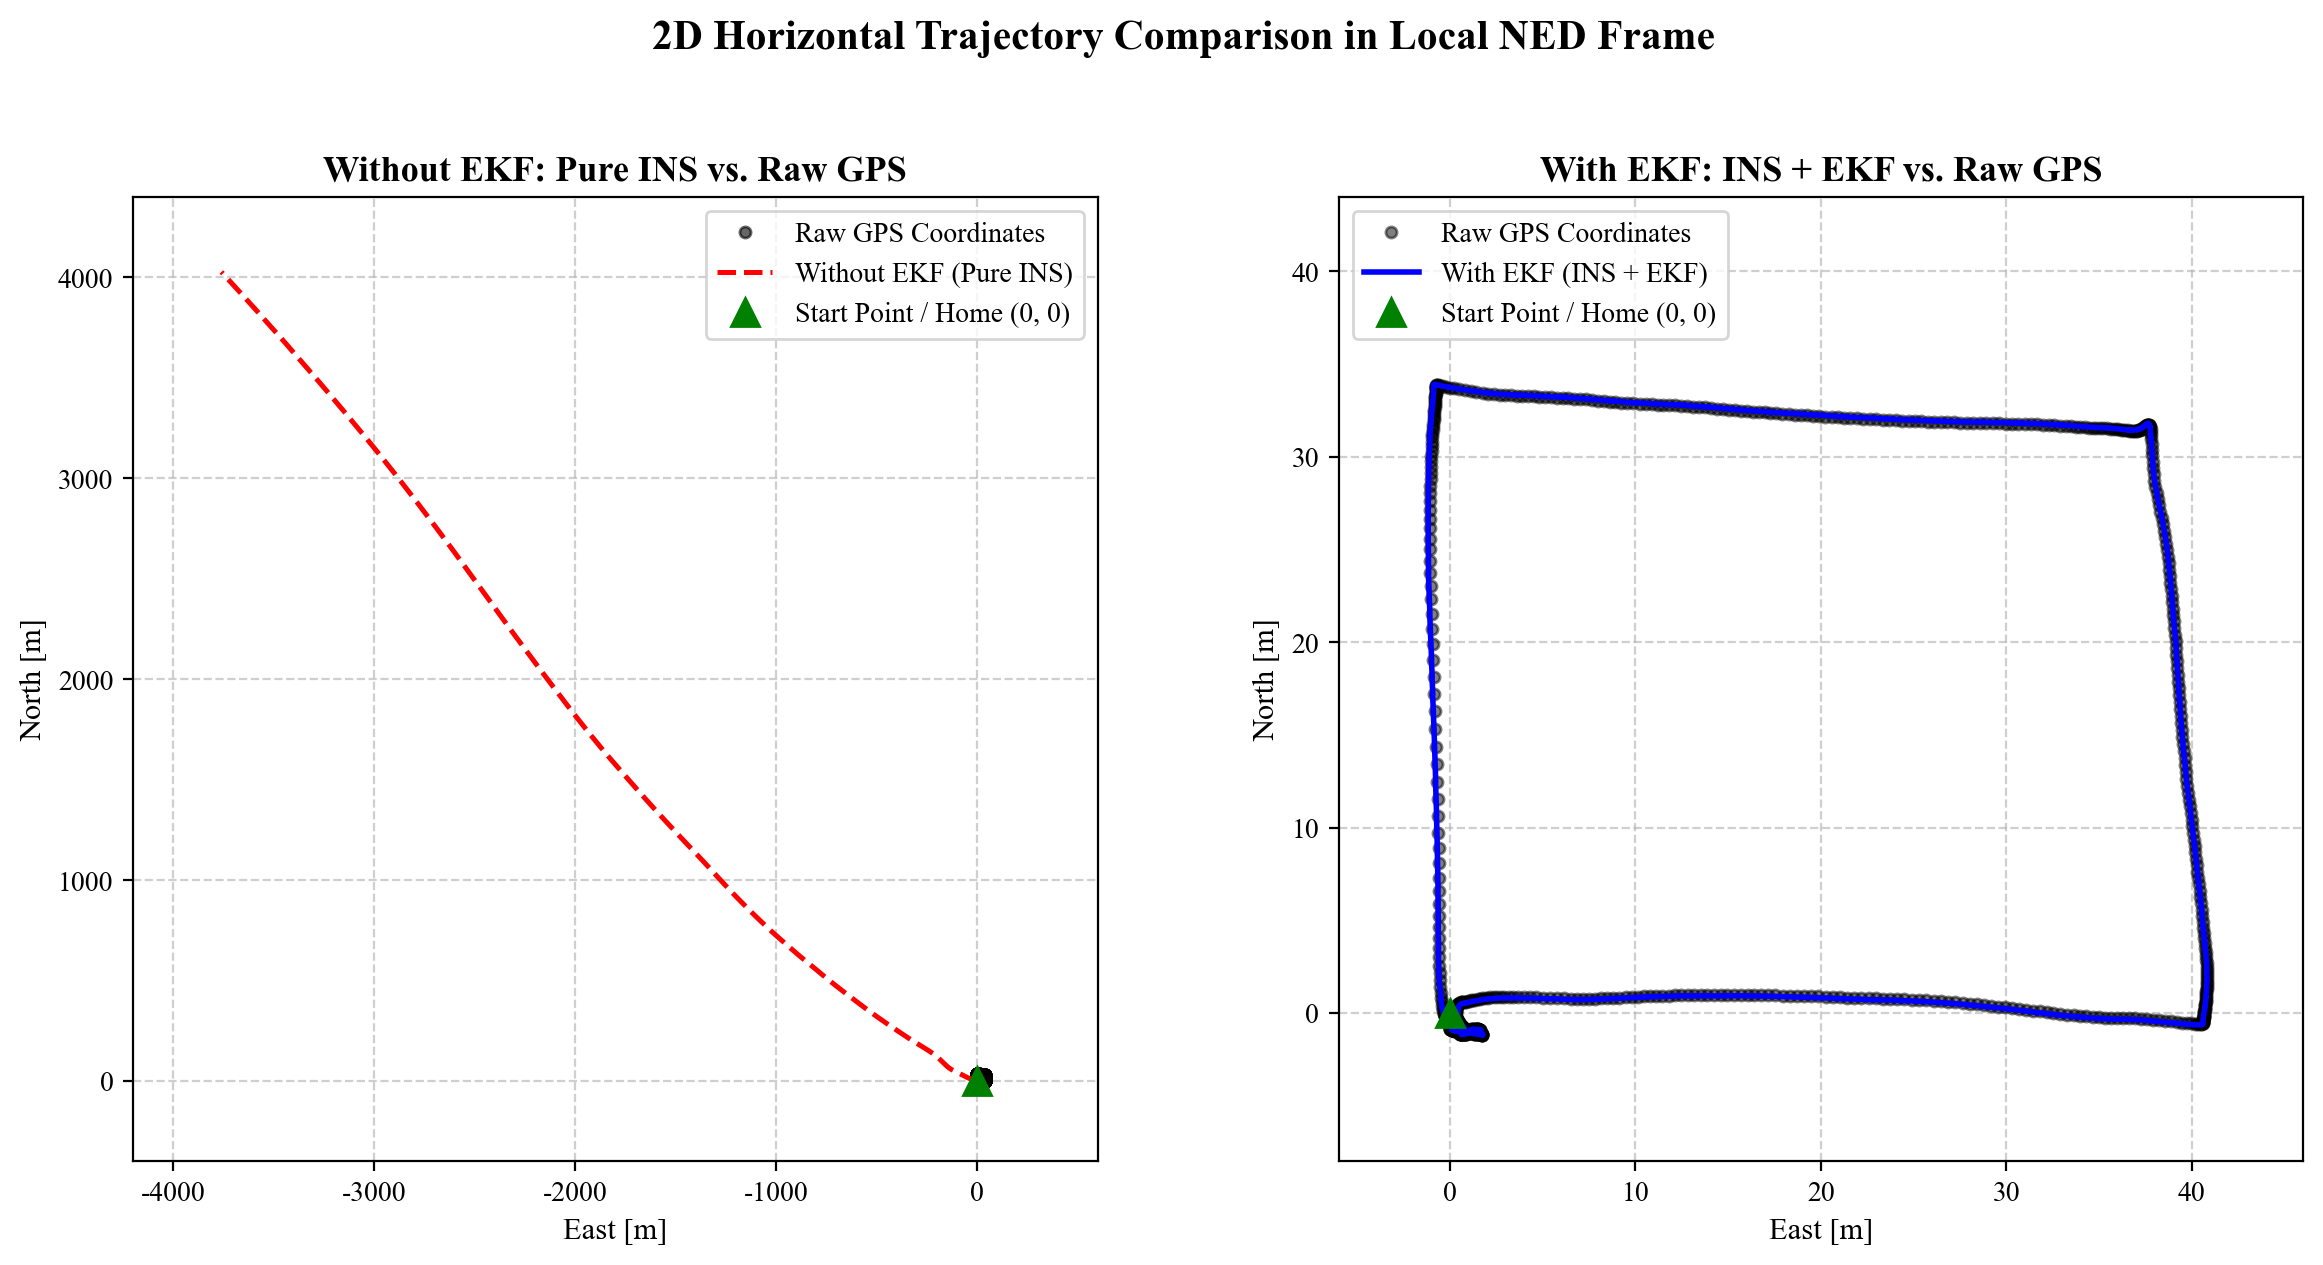

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.8), dpi=200)
plt.subplots_adjust(wspace=0.25)

# GRAFIK KIRI: Tanpa EKF (Pure INS vs. Raw GPS)
axes[0].plot(df_gps['East_m'], df_gps['North_m'], 'ko', markersize=4, alpha=0.6, label='Raw GPS Coordinates')
if df_ins is not None:
    axes[0].plot(df_ins['East_m'], df_ins['North_m'], 'r--', linewidth=1.8, label='Without EKF (Pure INS)')
axes[0].plot(0, 0, 'g^', markersize=10, zorder=5, label='Start Point / Home (0, 0)')

axes[0].set_xlim(-4200, 600)
axes[0].set_ylim(-400, 4400)
axes[0].set_aspect('equal', adjustable='box')
axes[0].set_title('Without EKF: Pure INS vs. Raw GPS', fontsize=13, fontweight='bold')
axes[0].set_xlabel('East [m]', fontsize=11)
axes[0].set_ylabel('North [m]', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='upper right', fontsize=10)

# GRAFIK KANAN: Menggunakan EKF (INS + EKF vs. Raw GPS)
axes[1].plot(df_gps['East_m'], df_gps['North_m'], 'ko', markersize=4, alpha=0.5, label='Raw GPS Coordinates')
axes[1].plot(df_ekf['East_m'], df_ekf['North_m'], 'b-', linewidth=2.0, label='With EKF (INS + EKF)')
axes[1].plot(0, 0, 'g^', markersize=10, zorder=5, label='Start Point / Home (0, 0)')

axes[1].set_xlim(-6, 46)
axes[1].set_ylim(-8, 44)
axes[1].set_aspect('equal', adjustable='box')
axes[1].set_title('With EKF: INS + EKF vs. Raw GPS', fontsize=13, fontweight='bold')
axes[1].set_xlabel('East [m]', fontsize=11)
axes[1].set_ylabel('North [m]', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='upper left', fontsize=10)

fig.suptitle('2D Horizontal Trajectory Comparison in Local NED Frame', fontsize=15, fontweight='bold', y=0.98)
plt.savefig('trajectory_2d_equal_size.png', bbox_inches='tight')
plt.show()

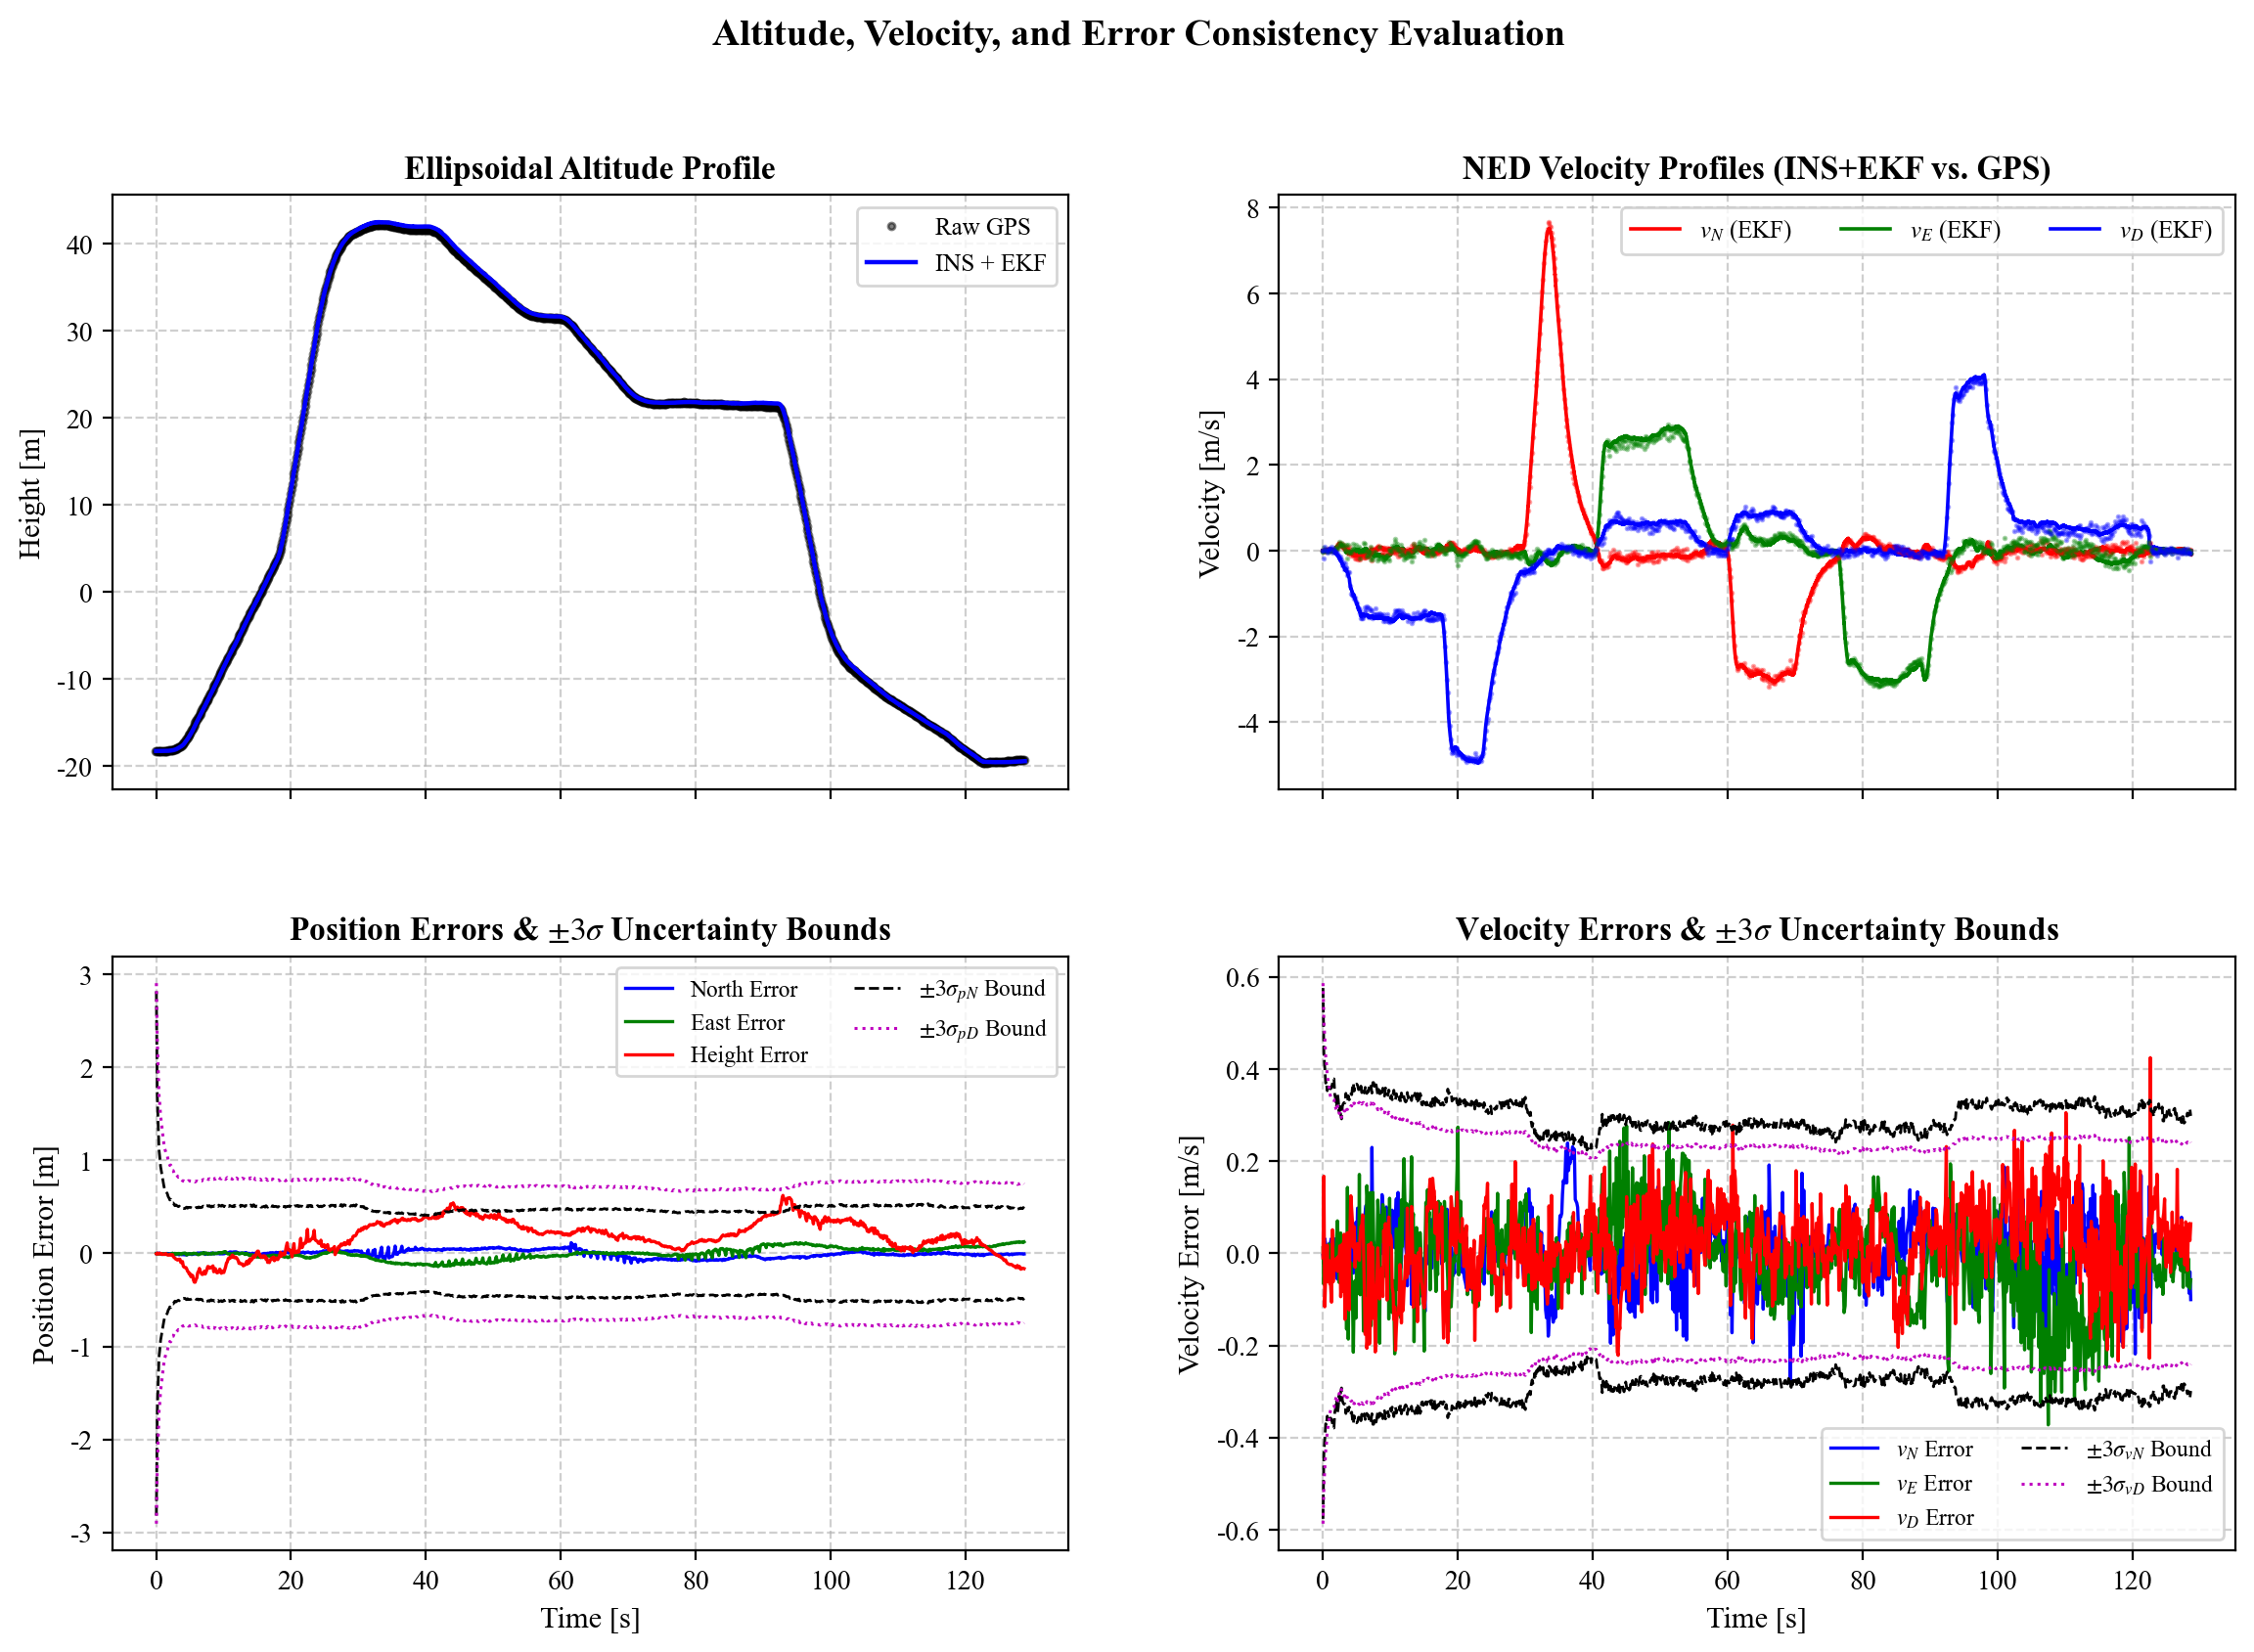

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=200, sharex=True)
plt.subplots_adjust(hspace=0.28, wspace=0.22)

# 1. Profil Ketinggian Elipsoid
axes[0, 0].plot(df_gps['t_sec'], df_gps['altitude_ellipsoid_m'], 'ko', markersize=2.5, alpha=0.5, label='Raw GPS')
axes[0, 0].plot(df_ekf['t_sec'], df_ekf['height_m'], 'b-', linewidth=1.6, label='INS + EKF')
axes[0, 0].set_title('Ellipsoidal Altitude Profile', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Height [m]', fontsize=11)
axes[0, 0].grid(True, linestyle='--', alpha=0.6)
axes[0, 0].legend(fontsize=9)

# 2. Profil Kecepatan NED (v_N, v_E, v_D)
axes[0, 1].plot(df_ekf['t_sec'], df_ekf['v_N'], 'r-', linewidth=1.3, label=r'$v_N$ (EKF)')
axes[0, 1].plot(df_ekf['t_sec'], df_ekf['v_E'], 'g-', linewidth=1.3, label=r'$v_E$ (EKF)')
axes[0, 1].plot(df_ekf['t_sec'], df_ekf['v_D'], 'b-', linewidth=1.3, label=r'$v_D$ (EKF)')
axes[0, 1].plot(df_gps['t_sec'], df_gps['vel_n_m_s'], 'r.', markersize=2, alpha=0.35)
axes[0, 1].plot(df_gps['t_sec'], df_gps['vel_e_m_s'], 'g.', markersize=2, alpha=0.35)
axes[0, 1].plot(df_gps['t_sec'], df_gps['vel_d_m_s'], 'b.', markersize=2, alpha=0.35)
axes[0, 1].set_title('NED Velocity Profiles (INS+EKF vs. GPS)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Velocity [m/s]', fontsize=11)
axes[0, 1].grid(True, linestyle='--', alpha=0.6)
axes[0, 1].legend(fontsize=9, ncol=3)

# 3. Error Posisi NED terhadap Amplop +/- 3 Sigma (Groves Eq. 3.6)
t_ref = seri_ekf['t']
sig_pN_ref = np.interp(t_ref, df_ekf['t_sec'], df_ekf['sig_pN'])
sig_pD_ref = np.interp(t_ref, df_ekf['t_sec'], df_ekf['sig_pD'])

axes[1, 0].plot(t_ref, seri_ekf['err_n'], 'b-', linewidth=1.2, label='North Error')
axes[1, 0].plot(t_ref, seri_ekf['err_e'], 'g-', linewidth=1.2, label='East Error')
axes[1, 0].plot(t_ref, seri_ekf['err_h'], 'r-', linewidth=1.2, label='Height Error')
axes[1, 0].plot(t_ref,  3.0 * sig_pN_ref, 'k--', linewidth=1.0, label=r'$\pm 3\sigma_{pN}$ Bound')
axes[1, 0].plot(t_ref, -3.0 * sig_pN_ref, 'k--', linewidth=1.0)
axes[1, 0].plot(t_ref,  3.0 * sig_pD_ref, 'm:',  linewidth=1.1, label=r'$\pm 3\sigma_{pD}$ Bound')
axes[1, 0].plot(t_ref, -3.0 * sig_pD_ref, 'm:',  linewidth=1.1)
axes[1, 0].set_title(r'Position Errors & $\pm 3\sigma$ Uncertainty Bounds', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Time [s]', fontsize=11)
axes[1, 0].set_ylabel('Position Error [m]', fontsize=11)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)
axes[1, 0].legend(fontsize=8.5, ncol=2)

# 4. Error Kecepatan NED terhadap Amplop +/- 3 Sigma
sig_vN_ref = np.interp(t_ref, df_ekf['t_sec'], df_ekf['sig_vN'])
sig_vD_ref = np.interp(t_ref, df_ekf['t_sec'], df_ekf['sig_vD'])

axes[1, 1].plot(t_ref, seri_ekf['err_vn'], 'b-', linewidth=1.2, label=r'$v_N$ Error')
axes[1, 1].plot(t_ref, seri_ekf['err_ve'], 'g-', linewidth=1.2, label=r'$v_E$ Error')
axes[1, 1].plot(t_ref, seri_ekf['err_vd'], 'r-', linewidth=1.2, label=r'$v_D$ Error')
axes[1, 1].plot(t_ref,  3.0 * sig_vN_ref, 'k--', linewidth=1.0, label=r'$\pm 3\sigma_{vN}$ Bound')
axes[1, 1].plot(t_ref, -3.0 * sig_vN_ref, 'k--', linewidth=1.0)
axes[1, 1].plot(t_ref,  3.0 * sig_vD_ref, 'm:',  linewidth=1.1, label=r'$\pm 3\sigma_{vD}$ Bound')
axes[1, 1].plot(t_ref, -3.0 * sig_vD_ref, 'm:',  linewidth=1.1)
axes[1, 1].set_title(r'Velocity Errors & $\pm 3\sigma$ Uncertainty Bounds', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Time [s]', fontsize=11)
axes[1, 1].set_ylabel('Velocity Error [m/s]', fontsize=11)
axes[1, 1].grid(True, linestyle='--', alpha=0.6)
axes[1, 1].legend(fontsize=8.5, ncol=2)

fig.suptitle('Altitude, Velocity, and Error Consistency Evaluation', fontsize=14, fontweight='bold', y=0.98)
plt.savefig('altitude_velocity_consistency.png', bbox_inches='tight')
plt.show()

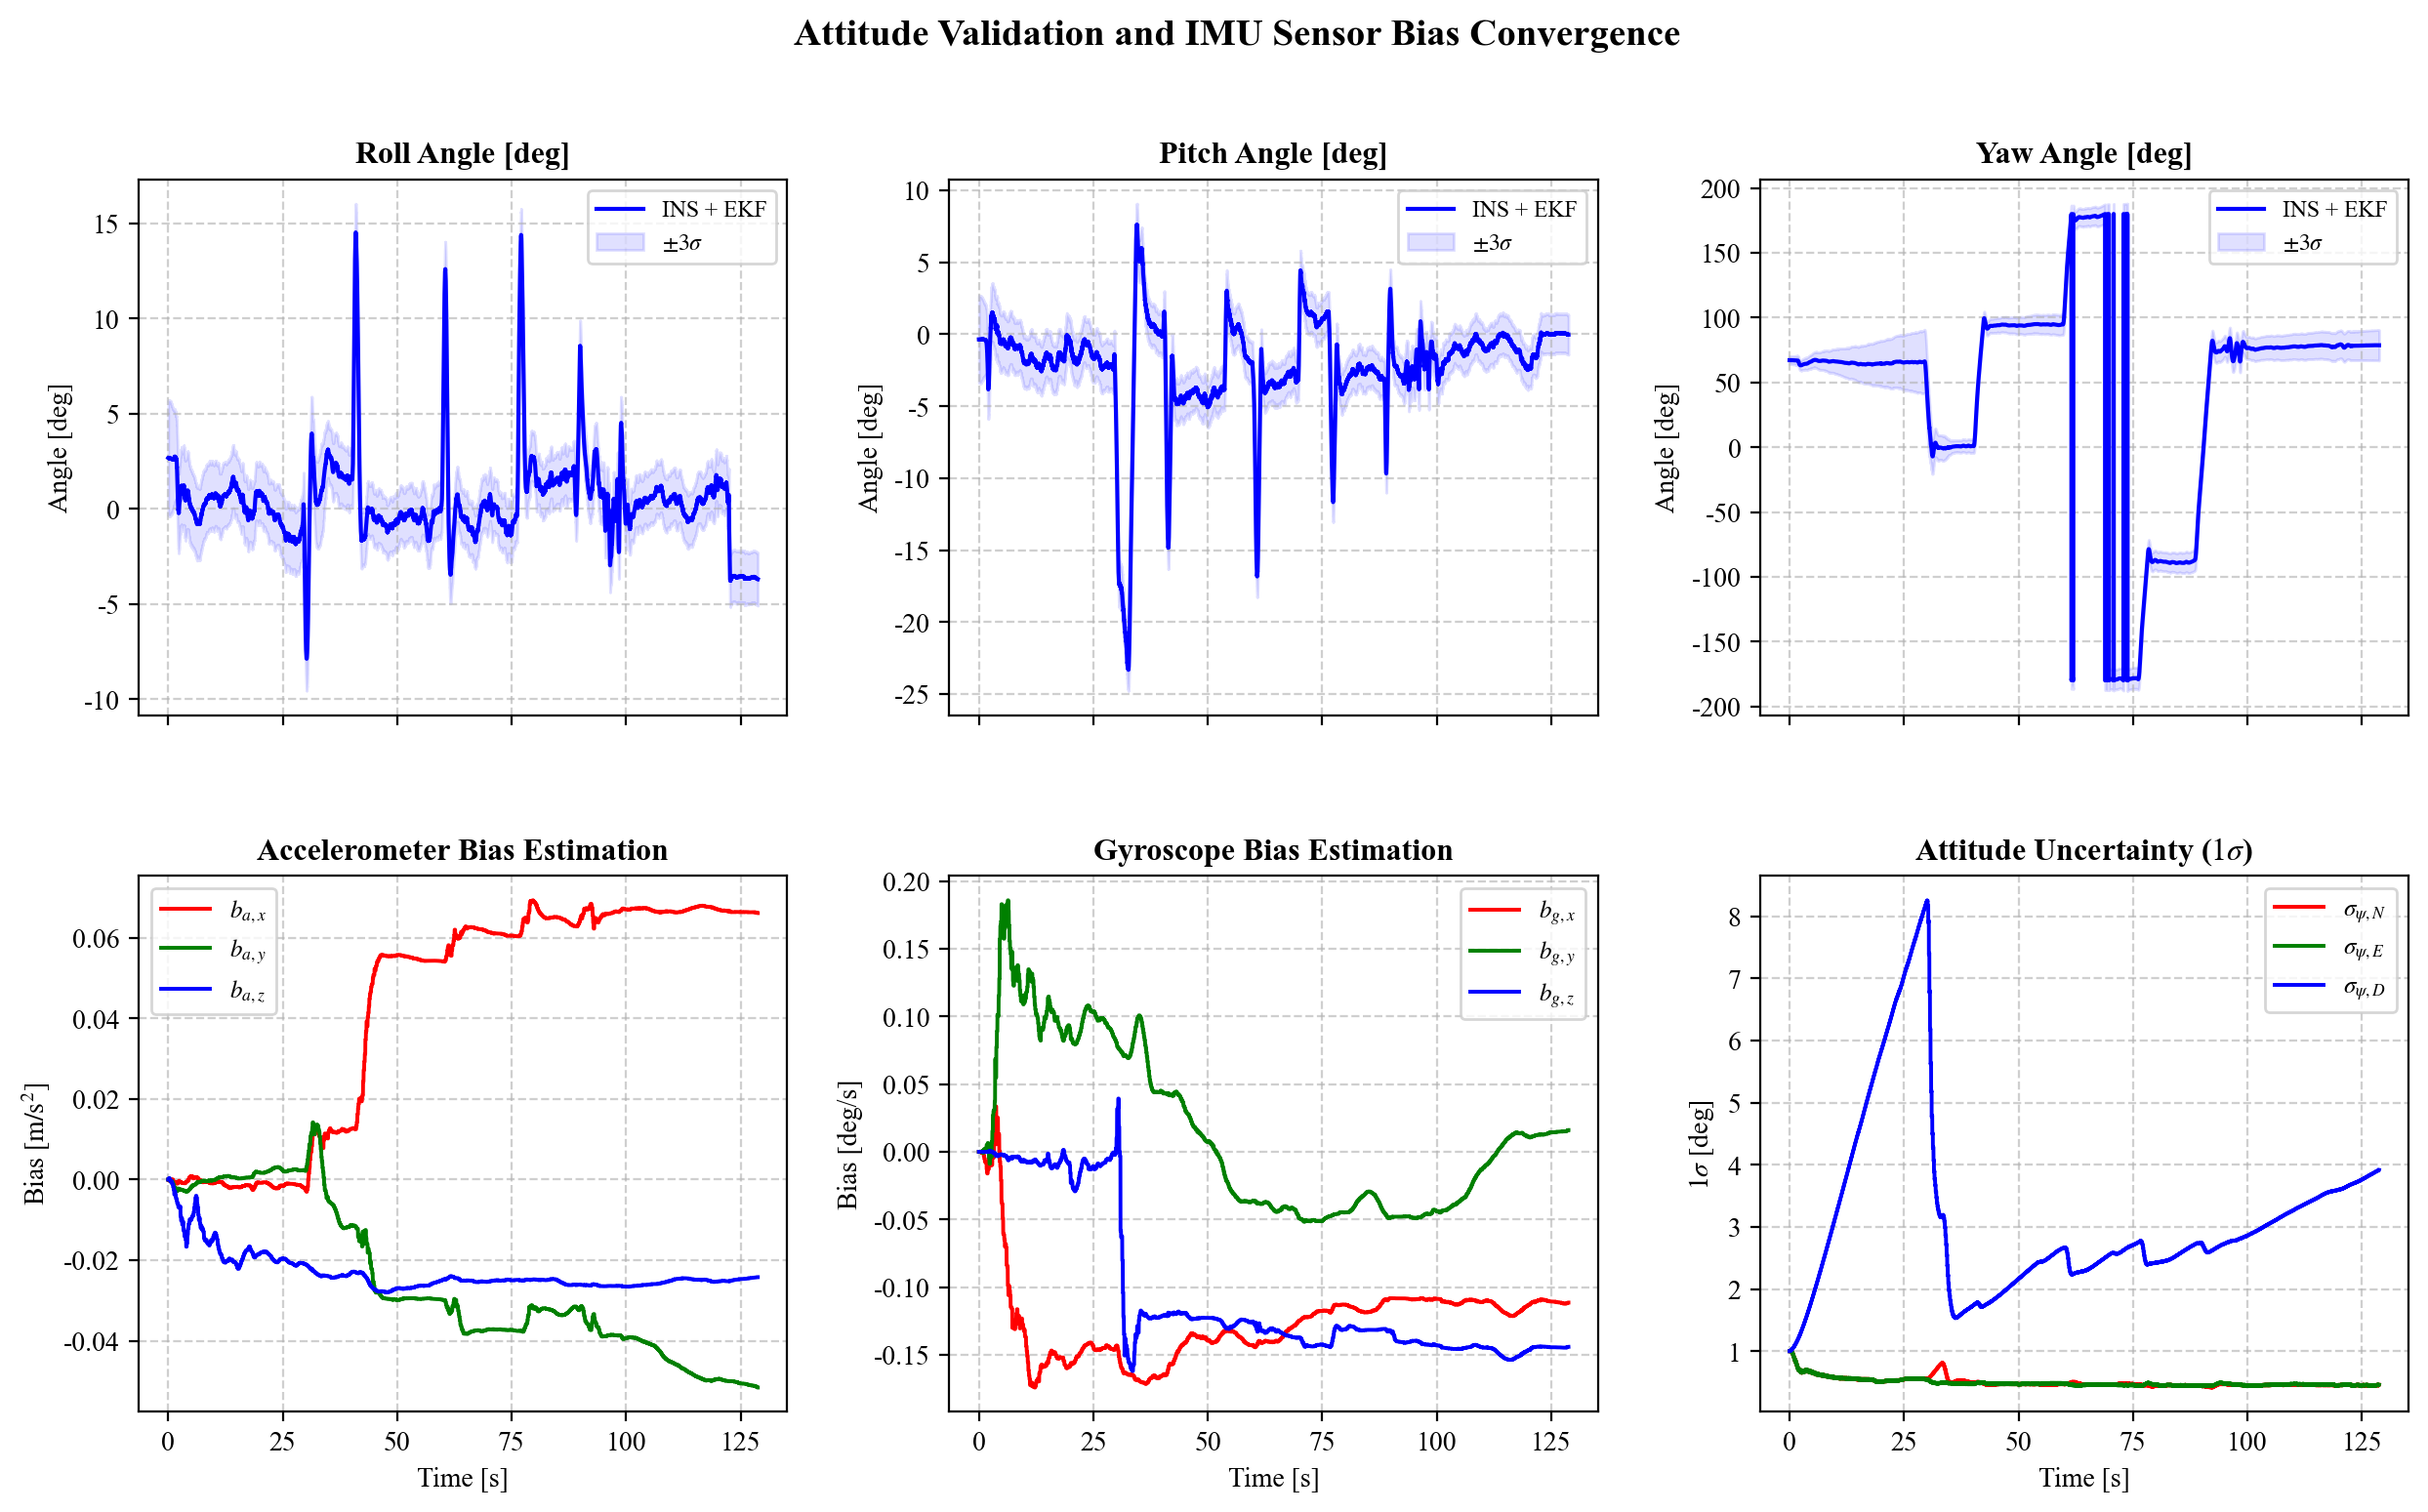

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2), dpi=200, sharex=True)
plt.subplots_adjust(hspace=0.30, wspace=0.25)

# Baris Atas: Perbandingan Sudut Euler (EKF vs. PX4 vehicle_attitude)
att_pairs = [
    ('roll_deg',  'Roll Angle [deg]',  'sig_psiN'),
    ('pitch_deg', 'Pitch Angle [deg]', 'sig_psiE'),
    ('yaw_deg',   'Yaw Angle [deg]',   'sig_psiD'),
]

for col_idx, (col_name, title_str, sig_col) in enumerate(att_pairs):
    ax = axes[0, col_idx]
    if df_att is not None:
        ax.plot(df_att['t_sec'], df_att[col_name], 'k--', linewidth=1.2, alpha=0.75, label='PX4 Reference')
    ax.plot(df_ekf['t_sec'], df_ekf[col_name], 'b-', linewidth=1.5, label='INS + EKF')

    # Konversi sig_psi (radian) ke derajat untuk pita ketidakpastian 3-sigma
    sig_deg = 3.0 * np.degrees(df_ekf[sig_col])
    ax.fill_between(df_ekf['t_sec'], df_ekf[col_name] - sig_deg, df_ekf[col_name] + sig_deg,
                    color='b', alpha=0.12, label=r'$\pm 3\sigma$')

    ax.set_title(title_str, fontsize=11.5, fontweight='bold')
    ax.set_ylabel('Angle [deg]', fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(fontsize=8.5)

# Baris Bawah: Konvergensi Bias Akselerometer & Giroskop + Ketidakpastian Sikap (3-sigma)
axes[1, 0].plot(df_ekf['t_sec'], df_ekf['bias_ax'], 'r-', linewidth=1.4, label=r'$b_{a,x}$')
axes[1, 0].plot(df_ekf['t_sec'], df_ekf['bias_ay'], 'g-', linewidth=1.4, label=r'$b_{a,y}$')
axes[1, 0].plot(df_ekf['t_sec'], df_ekf['bias_az'], 'b-', linewidth=1.4, label=r'$b_{a,z}$')
axes[1, 0].set_title('Accelerometer Bias Estimation', fontsize=11.5, fontweight='bold')
axes[1, 0].set_xlabel('Time [s]', fontsize=10)
axes[1, 0].set_ylabel(r'Bias [$\mathrm{m/s^2}$]', fontsize=10)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)
axes[1, 0].legend(fontsize=9)

axes[1, 1].plot(df_ekf['t_sec'], np.degrees(df_ekf['bias_gx']), 'r-', linewidth=1.4, label=r'$b_{g,x}$')
axes[1, 1].plot(df_ekf['t_sec'], np.degrees(df_ekf['bias_gy']), 'g-', linewidth=1.4, label=r'$b_{g,y}$')
axes[1, 1].plot(df_ekf['t_sec'], np.degrees(df_ekf['bias_gz']), 'b-', linewidth=1.4, label=r'$b_{g,z}$')
axes[1, 1].set_title('Gyroscope Bias Estimation', fontsize=11.5, fontweight='bold')
axes[1, 1].set_xlabel('Time [s]', fontsize=10)
axes[1, 1].set_ylabel('Bias [deg/s]', fontsize=10)
axes[1, 1].grid(True, linestyle='--', alpha=0.6)
axes[1, 1].legend(fontsize=9)

axes[1, 2].plot(df_ekf['t_sec'], np.degrees(df_ekf['sig_psiN']), 'r-', linewidth=1.4, label=r'$\sigma_{\psi,N}$')
axes[1, 2].plot(df_ekf['t_sec'], np.degrees(df_ekf['sig_psiE']), 'g-', linewidth=1.4, label=r'$\sigma_{\psi,E}$')
axes[1, 2].plot(df_ekf['t_sec'], np.degrees(df_ekf['sig_psiD']), 'b-', linewidth=1.4, label=r'$\sigma_{\psi,D}$')
axes[1, 2].set_title(r'Attitude Uncertainty ($1\sigma$)', fontsize=11.5, fontweight='bold')
axes[1, 2].set_xlabel('Time [s]', fontsize=10)
axes[1, 2].set_ylabel(r'$1\sigma$ [deg]', fontsize=10)
axes[1, 2].grid(True, linestyle='--', alpha=0.6)
axes[1, 2].legend(fontsize=9)

fig.suptitle('Attitude Validation and IMU Sensor Bias Convergence', fontsize=14, fontweight='bold', y=0.98)
plt.savefig('attitude_and_imu_biases.png', bbox_inches='tight')
plt.show()

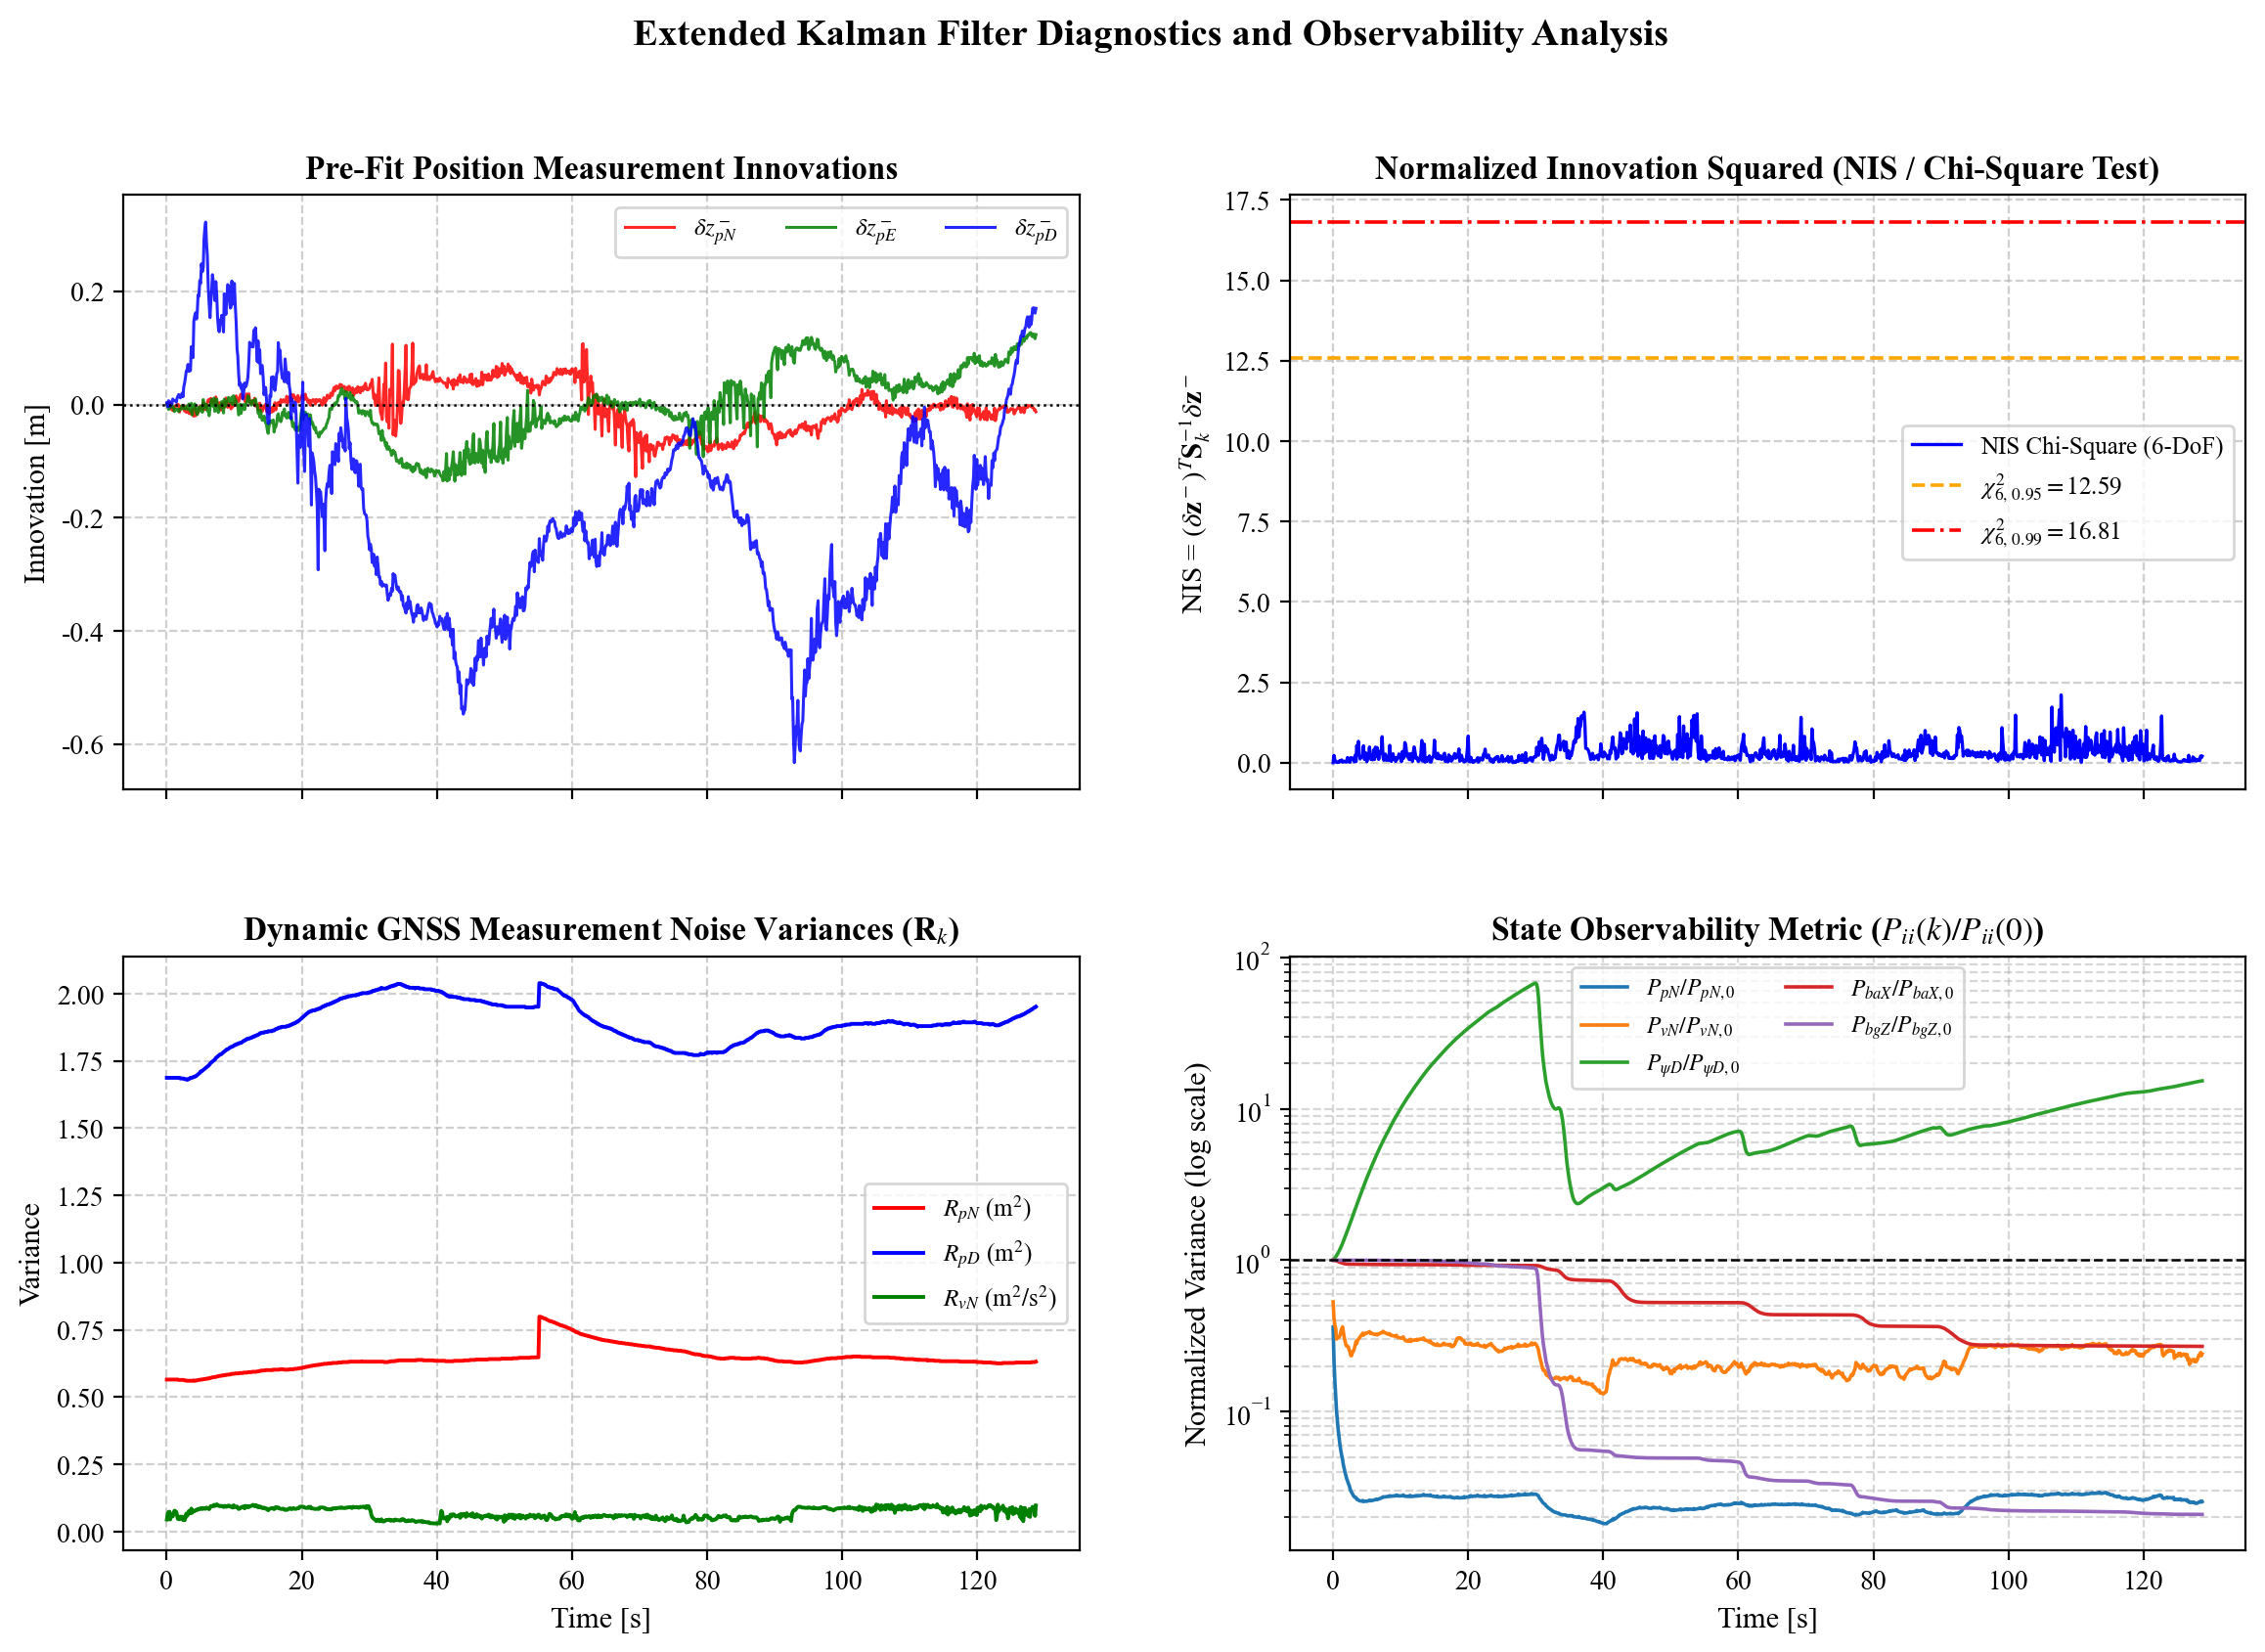

,Metrik Diagnostik,Nilai
0,NIS Chi-Square Mean (6-DoF),0.3102
1,NIS Chi-Square Median,0.2182
2,NIS Chi-Square Max,2.1058
3,Persentase NIS > Ambang 95% (%),0.0000
4,Final Normalized P (Pos North),0.0254
5,Final Normalized P (Yaw / Psi_D),15.3095
6,Final Normalized P (Accel Bias X),0.2696
7,Final Normalized P (Gyro Bias Z),0.0209


In [7]:
CHI2_6DOF_95 = 12.5916
CHI2_6DOF_99 = 16.8119

fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=200, sharex=True)
plt.subplots_adjust(hspace=0.28, wspace=0.22)

# 1. Pre-Fit Position Innovation (dz_minus)
axes[0, 0].plot(df_diag['t_sec'], df_diag['dz_pN'], 'r-', linewidth=1.1, alpha=0.85, label=r'$\delta z_{pN}^-$')
axes[0, 0].plot(df_diag['t_sec'], df_diag['dz_pE'], 'g-', linewidth=1.1, alpha=0.85, label=r'$\delta z_{pE}^-$')
axes[0, 0].plot(df_diag['t_sec'], df_diag['dz_pD'], 'b-', linewidth=1.1, alpha=0.85, label=r'$\delta z_{pD}^-$')
axes[0, 0].axhline(0.0, color='k', linestyle=':', linewidth=0.9)
axes[0, 0].set_title('Pre-Fit Position Measurement Innovations', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Innovation [m]', fontsize=11)
axes[0, 0].grid(True, linestyle='--', alpha=0.6)
axes[0, 0].legend(fontsize=9, ncol=3)

# 2. Statistik Uji Chi-Square NIS (Baseline untuk AIME Groves Bab 17)
axes[0, 1].plot(df_diag['t_sec'], df_diag['nis_chi2'], 'b-', linewidth=1.2, label='NIS Chi-Square (6-DoF)')
axes[0, 1].axhline(CHI2_6DOF_95, color='orange', linestyle='--', linewidth=1.3,
                   label=rf'$\chi^2_{{6,\,0.95}} = {CHI2_6DOF_95:.2f}$')
axes[0, 1].axhline(CHI2_6DOF_99, color='red', linestyle='-.', linewidth=1.3,
                   label=rf'$\chi^2_{{6,\,0.99}} = {CHI2_6DOF_99:.2f}$')
axes[0, 1].set_title('Normalized Innovation Squared (NIS / Chi-Square Test)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel(r'NIS = $(\delta\mathbf{z}^-)^T \mathbf{S}_k^{-1} \delta\mathbf{z}^-$', fontsize=10.5)
axes[0, 1].grid(True, linestyle='--', alpha=0.6)
axes[0, 1].legend(fontsize=9)

# 3. Varians Pengukuran Dinamis GNSS R_k (Groves Eq. 3.11)
axes[1, 0].plot(df_diag['t_sec'], df_diag['r_pN'], 'r-', linewidth=1.4, label=r'$R_{pN}$ ($\mathrm{m^2}$)')
axes[1, 0].plot(df_diag['t_sec'], df_diag['r_pD'], 'b-', linewidth=1.4, label=r'$R_{pD}$ ($\mathrm{m^2}$)')
axes[1, 0].plot(df_diag['t_sec'], df_diag['r_vN'], 'g-', linewidth=1.4, label=r'$R_{vN}$ ($\mathrm{m^2/s^2}$)')
axes[1, 0].set_title(r'Dynamic GNSS Measurement Noise Variances ($\mathbf{R}_k$)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Time [s]', fontsize=11)
axes[1, 0].set_ylabel('Variance', fontsize=11)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)
axes[1, 0].legend(fontsize=9)

# 4. Metrik Observability Kovariansi Ternormalisasi P_ii(k) / P_ii(0) (Groves Eq. 3.71)
axes[1, 1].semilogy(df_diag['t_sec'], df_diag['normP_pN'],   linewidth=1.3, label=r'$P_{pN}/P_{pN,0}$')
axes[1, 1].semilogy(df_diag['t_sec'], df_diag['normP_vN'],   linewidth=1.3, label=r'$P_{vN}/P_{vN,0}$')
axes[1, 1].semilogy(df_diag['t_sec'], df_diag['normP_psiD'], linewidth=1.3, label=r'$P_{\psi D}/P_{\psi D,0}$')
axes[1, 1].semilogy(df_diag['t_sec'], df_diag['normP_baX'],  linewidth=1.3, label=r'$P_{baX}/P_{baX,0}$')
axes[1, 1].semilogy(df_diag['t_sec'], df_diag['normP_bgZ'],  linewidth=1.3, label=r'$P_{bgZ}/P_{bgZ,0}$')
axes[1, 1].axhline(1.0, color='k', linestyle='--', linewidth=0.9)
axes[1, 1].set_title(r'State Observability Metric ($P_{ii}(k) / P_{ii}(0)$)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Time [s]', fontsize=11)
axes[1, 1].set_ylabel('Normalized Variance (log scale)', fontsize=11)
axes[1, 1].grid(True, which='both', linestyle='--', alpha=0.5)
axes[1, 1].legend(fontsize=8.5, ncol=2)

fig.suptitle('Extended Kalman Filter Diagnostics and Observability Analysis', fontsize=14, fontweight='bold', y=0.98)
plt.savefig('ekf_diagnostics_observability.png', bbox_inches='tight')
plt.show()

# Ringkasan Statistik Diagnostik EKF
nis_exceed_95 = np.mean(df_diag['nis_chi2'] > CHI2_6DOF_95) * 100.0
summary_diag = pd.DataFrame([
    {'Metrik Diagnostik': 'NIS Chi-Square Mean (6-DoF)',         'Nilai': df_diag['nis_chi2'].mean()},
    {'Metrik Diagnostik': 'NIS Chi-Square Median',               'Nilai': df_diag['nis_chi2'].median()},
    {'Metrik Diagnostik': 'NIS Chi-Square Max',                  'Nilai': df_diag['nis_chi2'].max()},
    {'Metrik Diagnostik': 'Persentase NIS > Ambang 95% (%)',     'Nilai': nis_exceed_95},
    {'Metrik Diagnostik': 'Final Normalized P (Pos North)',      'Nilai': df_diag['normP_pN'].iloc[-1]},
    {'Metrik Diagnostik': 'Final Normalized P (Yaw / Psi_D)',    'Nilai': df_diag['normP_psiD'].iloc[-1]},
    {'Metrik Diagnostik': 'Final Normalized P (Accel Bias X)',   'Nilai': df_diag['normP_baX'].iloc[-1]},
    {'Metrik Diagnostik': 'Final Normalized P (Gyro Bias Z)',    'Nilai': df_diag['normP_bgZ'].iloc[-1]},
])
display(summary_diag.round(4))